# Delivery Delay Root-Cause Analysis - Olist
**Priyangi Singh Chouhan**

This notebook walks through each business question in order: **question -> SQL query -> result -> chart -> insight**.
It reads the queries from `sql/analysis.sql` and the database built by `src/01_clean.py`, so run the scripts in
`src/` first (see README). Insight text is filled from `results/metrics.json`, so the numbers always match the
other documents.

In [1]:
import json
import re
import sqlite3
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

# Work whether the notebook is opened from the project root or from /notebooks
ROOT = Path("..").resolve() if Path("../sql").exists() else Path(".").resolve()
conn = sqlite3.connect(ROOT / "data" / "processed" / "olist.db")
SQL_TEXT = (ROOT / "sql" / "analysis.sql").read_text(encoding="utf-8")
m = json.loads((ROOT / "results" / "metrics.json").read_text(encoding="utf-8"))
A, I = m["analysis"], m["impact"]


def get_query(name):
    """Return the SQL text of one named query from sql/analysis.sql."""
    blocks = re.split(r"^-- name:\s*", SQL_TEXT, flags=re.MULTILINE)
    for block in blocks[1:]:
        title, body = block.split("\n", 1)
        if title.strip() == name:
            return body.strip()
    raise KeyError(name)


def run(name, show_sql=True):
    """Print the query, run it and return the result as a DataFrame."""
    sql = get_query(name)
    if show_sql:
        print(sql)
    return pd.read_sql_query(sql, conn)


def chart(file_name, width=750):
    display(Image(filename=str(ROOT / "results" / "charts" / file_name), width=width))


def insight(text):
    display(Markdown("**Insight:** " + text))

## Q1. How big is the late-delivery problem, and what is the monthly trend?

In [2]:
run("q01_overall_kpis")

-- question: Q1. How big is the late-delivery problem overall?
SELECT
    COUNT(*)                                             AS delivered_orders,
    SUM(is_late)                                         AS late_orders,
    ROUND(100.0 * AVG(is_late), 2)                       AS late_rate_pct,
    ROUND(100.0 * (1 - AVG(is_late)), 2)                 AS on_time_rate_pct,
    ROUND(AVG(CASE WHEN is_late = 1 THEN delay_days END), 2)  AS avg_delay_days_late_orders,
    ROUND(AVG(review_score), 2)                          AS avg_review_score,
    ROUND(100.0 * SUM(is_bad_review) / SUM(has_review), 2)    AS bad_review_pct,
    (SELECT ROUND(100.0 * AVG(sla_breach), 2)
       FROM analysis_order_sellers
      WHERE sla_breach IS NOT NULL)                      AS seller_sla_breach_pct
FROM analysis_orders;


,delivered_orders,late_orders,late_rate_pct,on_time_rate_pct,avg_delay_days_late_orders,avg_review_score,bad_review_pct,seller_sla_breach_pct
0,96203,6531,6.79,93.21,10.62,4.16,12.8,8.86


In [3]:
run("q02_monthly_trend", show_sql=False)

,purchase_month,orders,late_orders,on_time_rate_pct,avg_delay_days_late_orders,bad_review_pct
0,2017-01,750,22,97.07,20.23,12.01
1,2017-02,1653,49,97.04,20.80,11.08
2,2017-03,2546,116,95.44,25.43,11.24
3,2017-04,2303,151,93.44,12.34,12.93
4,2017-05,3545,106,97.01,12.54,10.07
5,2017-06,3135,95,96.97,14.26,10.74
6,2017-07,3872,108,97.21,11.69,9.94
7,2017-08,4193,122,97.09,8.79,9.39
8,2017-09,4150,182,95.61,9.38,10.27
9,2017-10,4478,187,95.82,9.24,11.07


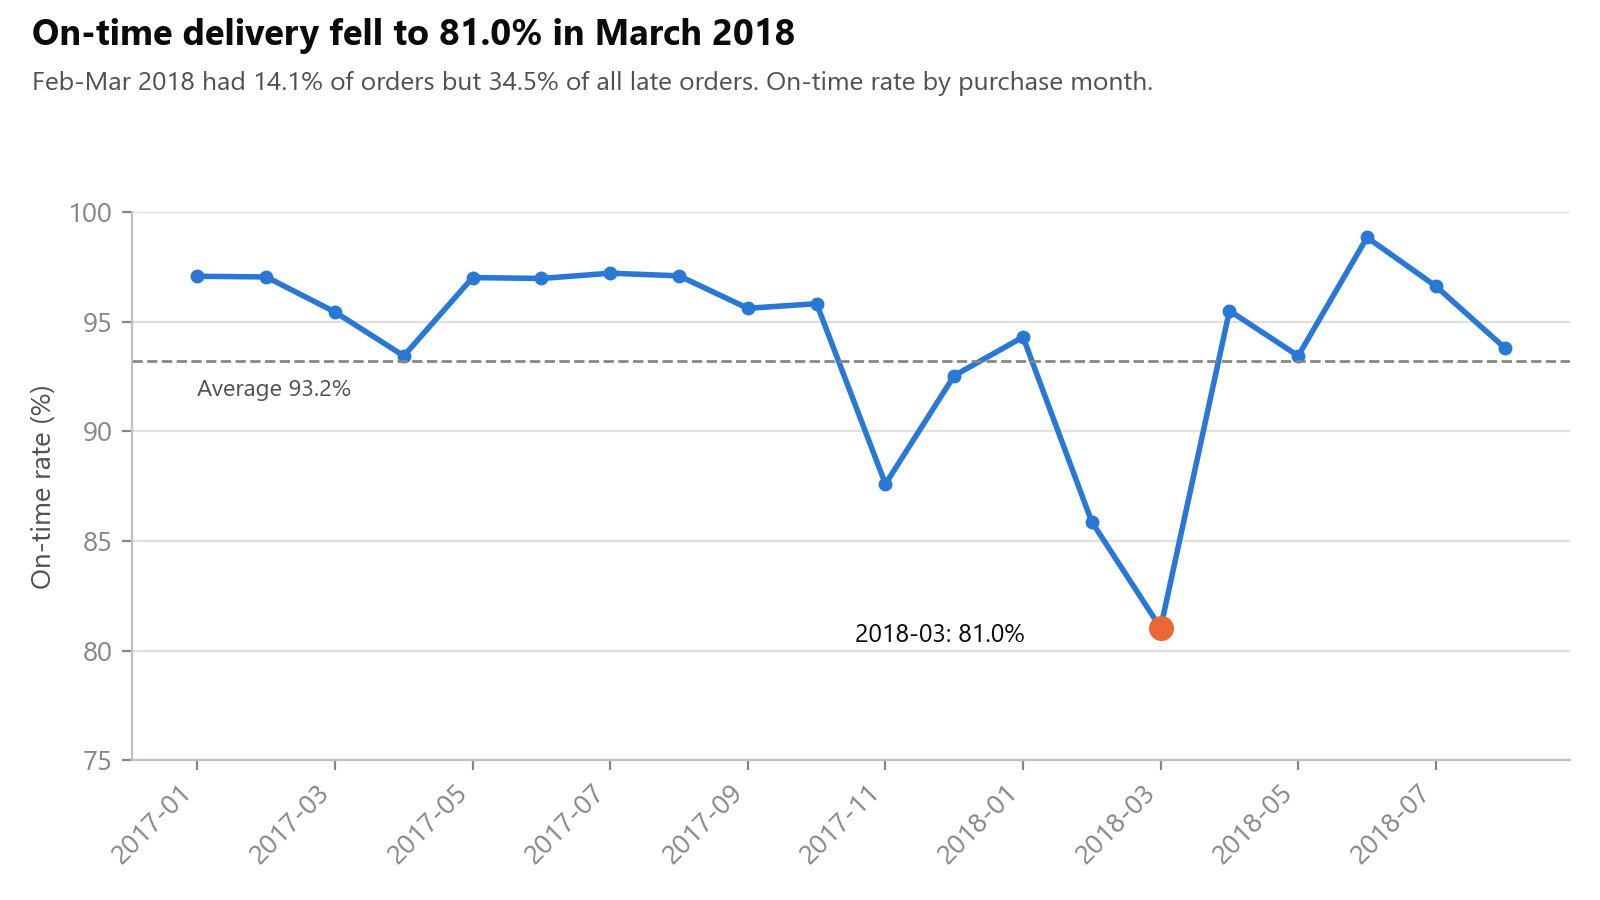

In [4]:
chart("01_monthly_on_time_rate.png")

In [5]:
insight(f"{A['on_time_rate_pct']}% of {A['delivered_orders']:,} orders arrived on time. "
        f"Feb-Mar 2018 had {A['feb_mar_2018_share_of_orders_pct']}% of orders but "
        f"{A['feb_mar_2018_share_of_late_pct']}% of late orders, so lateness comes in peaks.")

**Insight:** 93.21% of 96,203 orders arrived on time. Feb-Mar 2018 had 14.09% of orders but 34.51% of late orders, so lateness comes in peaks.

## Q2. How strongly does lateness affect reviews?

In [6]:
run("q03_review_late_vs_ontime")

-- question: Q2. How strongly does lateness affect review score and bad-review share?
SELECT
    CASE WHEN is_late = 1 THEN 'Late' ELSE 'On time' END AS delivery_status,
    COUNT(*)                                             AS reviewed_orders,
    ROUND(AVG(review_score), 2)                          AS avg_review_score,
    ROUND(100.0 * AVG(is_bad_review), 2)                 AS bad_review_pct,
    ROUND(100.0 * AVG(is_good_review), 2)                AS good_review_pct
FROM analysis_orders
WHERE has_review = 1
GROUP BY delivery_status
ORDER BY delivery_status;


,delivery_status,reviewed_orders,avg_review_score,bad_review_pct,good_review_pct
0,Late,6378,2.27,62.42,26.70
1,On time,89182,4.29,9.25,82.68


In [7]:
run("q04_review_by_delay_bucket", show_sql=False)

,delay_bucket,reviewed_orders,avg_review_score,bad_review_pct,good_review_pct
0,on time,89182,4.29,9.25,82.68
1,1-3 days,1851,3.29,32.14,53.16
2,4-7 days,1748,2.10,67.68,22.48
3,8-14 days,1446,1.67,80.15,11.00
4,15+ days,1333,1.72,78.32,12.53


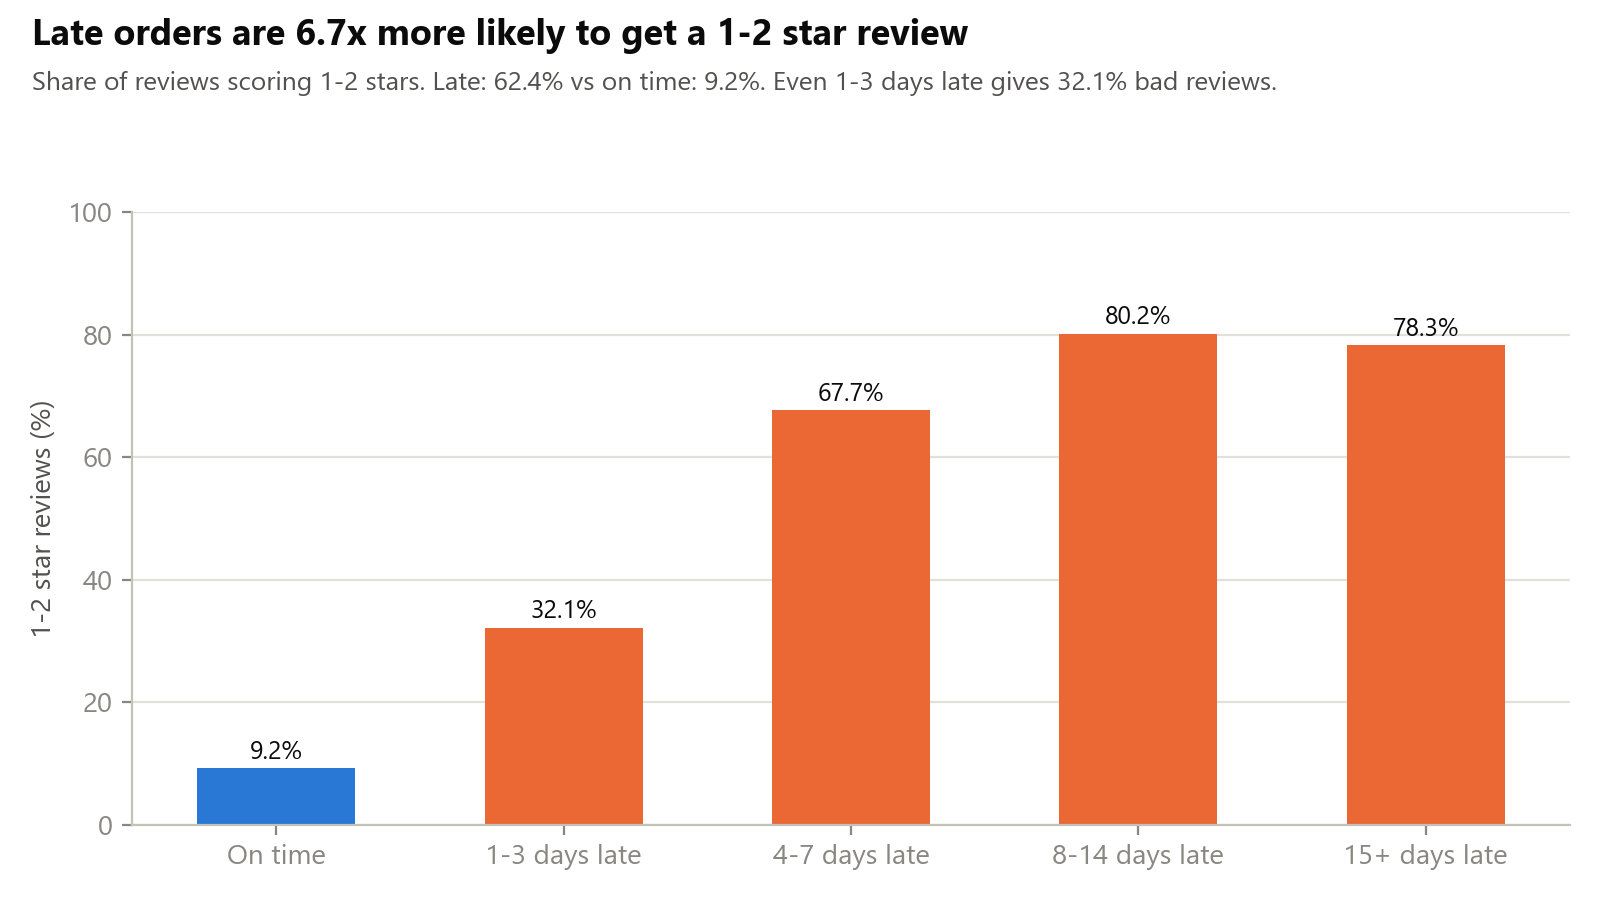

In [8]:
chart("02_bad_reviews_by_delay.png")

In [9]:
insight(f"Late orders get a 1-2 star review {A['bad_review_pct_late']}% of the time vs "
        f"{A['bad_review_pct_ontime']}% on time ({A['bad_review_multiple_late_vs_ontime']}x). "
        f"Even 1-3 days late gives {A['bad_review_pct_late_1_3_days']}%.")

**Insight:** Late orders get a 1-2 star review 62.42% of the time vs 9.25% on time (6.7x). Even 1-3 days late gives 32.14%.

## Q3. Where in the journey does the time go?

In [10]:
run("q05_stage_durations")

-- question: Q3. Where in the journey does time go? Average stage durations, late vs on-time
-- (only orders with valid timestamps: stage_valid = 1)
SELECT
    CASE WHEN is_late = 1 THEN 'Late' ELSE 'On time' END AS delivery_status,
    COUNT(*)                                             AS orders,
    ROUND(AVG(approval_days), 2)                         AS avg_approval_days,
    ROUND(AVG(seller_handling_days), 2)                  AS avg_seller_handling_days,
    ROUND(AVG(carrier_transit_days), 2)                  AS avg_carrier_transit_days,
    ROUND(AVG(actual_lead_days), 2)                      AS avg_actual_lead_days,
    ROUND(AVG(promised_lead_days), 2)                    AS avg_promised_lead_days
FROM analysis_orders
WHERE stage_valid = 1
GROUP BY delivery_status
ORDER BY delivery_status;


,delivery_status,orders,avg_approval_days,avg_seller_handling_days,avg_carrier_transit_days,avg_actual_lead_days,avg_promised_lead_days
0,Late,6506,0.50,5.55,27.89,33.94,22.63
1,On time,88313,0.39,2.62,8.01,11.03,23.73


In [11]:
run("q06_late_cause_split")

-- question: Q3. Is the delay mainly seller handling or carrier transit?
-- Each late order is put in one group: did any seller in the order miss its
-- handover deadline (SLA breach), or did the seller hand over on time and the
-- parcel still arrived late?
WITH order_sla AS (
    SELECT order_id, MAX(sla_breach) AS any_sla_breach
    FROM analysis_order_sellers
    GROUP BY order_id
)
SELECT
    CASE WHEN s.any_sla_breach = 1
         THEN 'Seller missed handover deadline'
         ELSE 'Seller on time, late after handover'
    END                                                  AS late_cause,
    COUNT(*)                                             AS late_orders,
    ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2)   AS share_of_late_orders_pct,
    ROUND(AVG(a.seller_handling_days), 2)                AS avg_seller_handling_days,
    ROUND(AVG(a.carrier_transit_days), 2)                AS avg_carrier_transit_days,
    ROUND(AVG(a.delay_days), 2)                          AS avg_d

,late_cause,late_orders,share_of_late_orders_pct,avg_seller_handling_days,avg_carrier_transit_days,avg_delay_days
0,"Seller on time, late after handover",4695,72.16,2.56,31.56,10.92
1,Seller missed handover deadline,1811,27.84,13.30,18.36,9.83


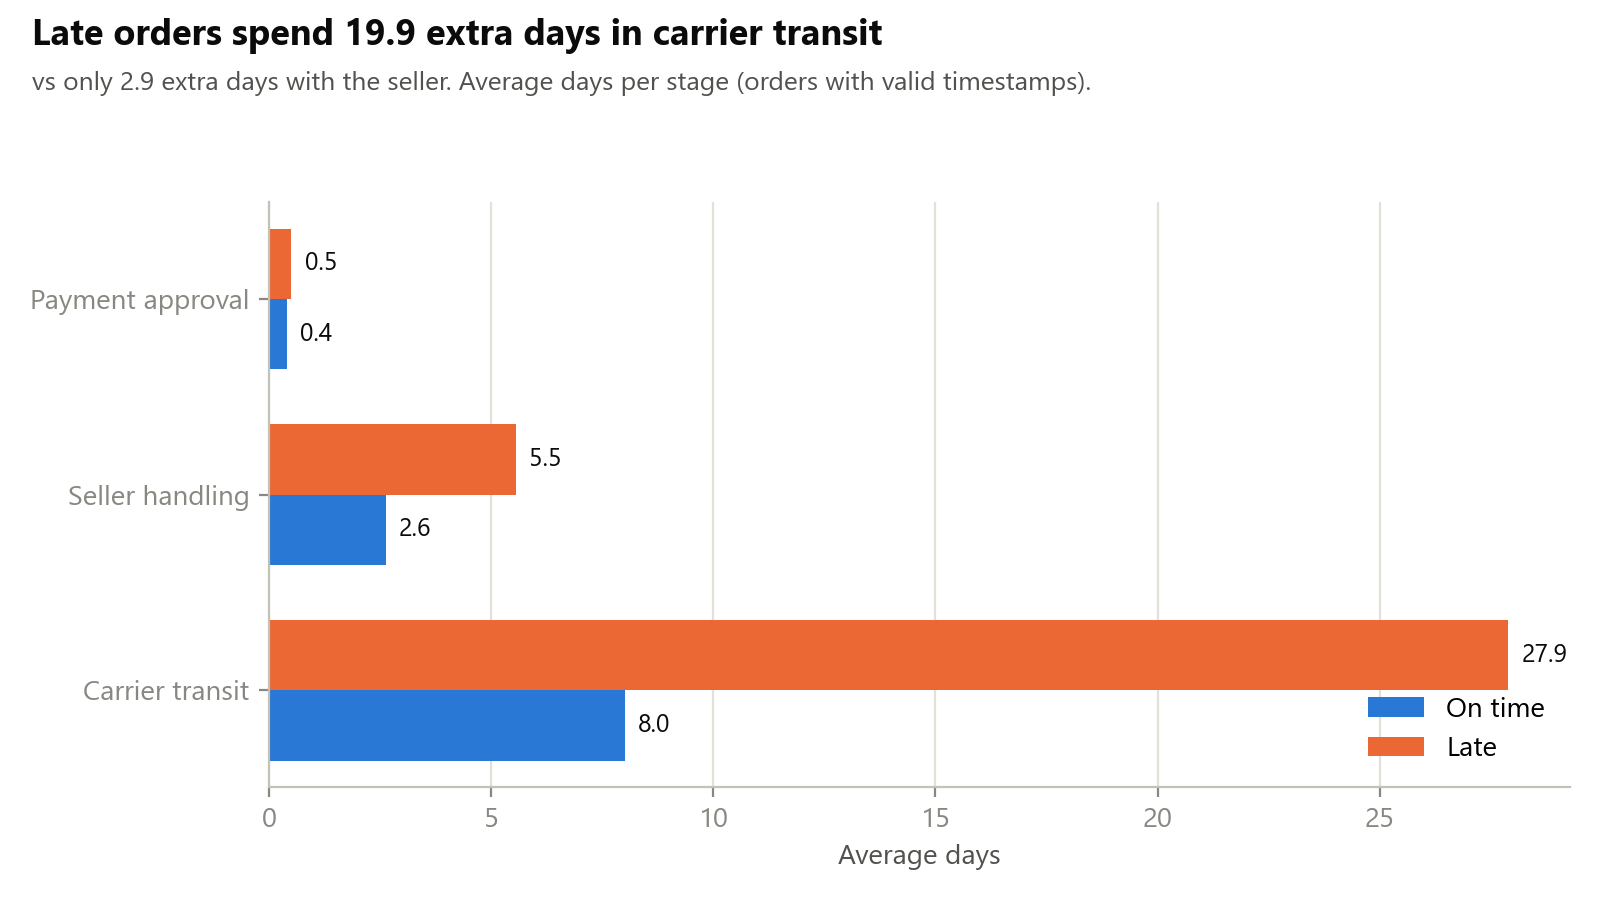

In [12]:
chart("03_stage_durations.png")

In [13]:
insight(f"Late orders spend {A['extra_transit_days_late']} extra days in carrier transit but only "
        f"{A['extra_handling_days_late']} extra days with the seller; {A['late_share_after_handover_pct']}% "
        "of late orders had a seller who met the handover deadline.")

**Insight:** Late orders spend 19.88 extra days in carrier transit but only 2.93 extra days with the seller; 72.16% of late orders had a seller who met the handover deadline.

## Q4. Which states and routes are worst?

In [14]:
run("q07_customer_state_late").head(10)

-- question: Q4. Which customer states have the highest late rates (min 300 orders)?
SELECT
    customer_state,
    COUNT(*)                                             AS orders,
    SUM(is_late)                                         AS late_orders,
    ROUND(100.0 * AVG(is_late), 2)                       AS late_rate_pct,
    ROUND(100.0 * SUM(is_late) / (SELECT SUM(is_late) FROM analysis_orders), 2)
                                                         AS share_of_all_late_pct,
    ROUND(AVG(CASE WHEN is_late = 1 THEN delay_days END), 2)  AS avg_delay_days_late_orders
FROM analysis_orders
GROUP BY customer_state
HAVING COUNT(*) >= 300
ORDER BY late_rate_pct DESC;


,customer_state,orders,late_orders,late_rate_pct,share_of_all_late_pct,avg_delay_days_late_orders
0,AL,396,85,21.46,1.30,9.54
1,MA,713,125,17.53,1.91,10.50
2,SE,332,51,15.36,0.78,16.20
3,PI,475,66,13.89,1.01,13.35
4,CE,1273,176,13.83,2.69,15.18
5,BA,3253,396,12.17,6.06,12.02
6,RJ,12310,1495,12.14,22.89,13.52
7,PA,942,106,11.25,1.62,12.82
8,ES,1992,214,10.74,3.28,11.30
9,PB,516,54,10.47,0.83,10.33


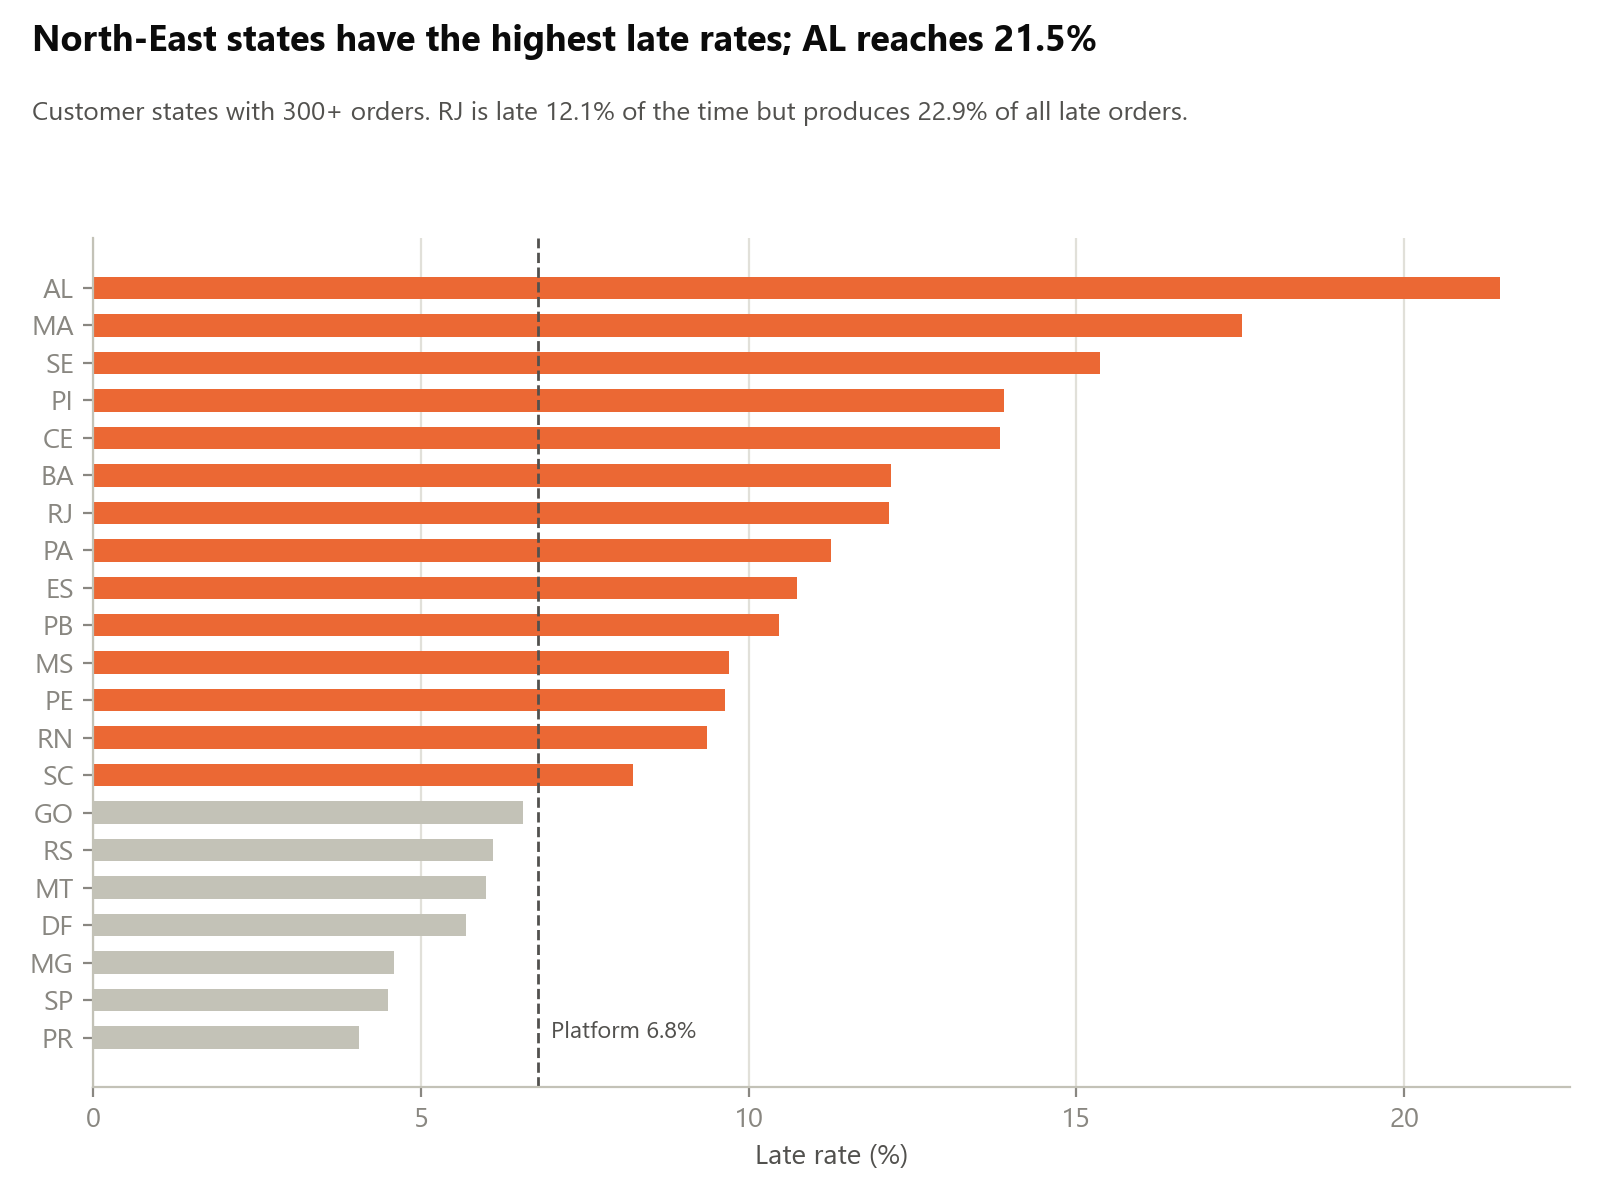

In [15]:
chart("05_state_late_rate.png", width=600)

In [16]:
run("q08_route_late").head(10)

-- question: Q4. Which seller-to-customer routes have the highest late rates and the most late orders (min 300 order-seller pairs)?
SELECT
    route,
    COUNT(*)                                             AS order_seller_pairs,
    SUM(is_late)                                         AS late_pairs,
    ROUND(100.0 * AVG(is_late), 2)                       AS late_rate_pct,
    RANK() OVER (ORDER BY AVG(is_late) DESC)             AS rank_by_late_rate,
    RANK() OVER (ORDER BY SUM(is_late) DESC)             AS rank_by_late_count
FROM analysis_order_sellers
GROUP BY route
HAVING COUNT(*) >= 300
ORDER BY late_pairs DESC;


,route,order_seller_pairs,late_pairs,late_rate_pct,rank_by_late_rate,rank_by_late_count
0,SP -> SP,31118,1430,4.60,26,1
1,SP -> RJ,8257,1157,14.01,3,2
2,SP -> MG,7543,394,5.22,24,3
3,SP -> BA,2337,297,12.71,5,4
4,SP -> RS,3652,238,6.52,19,5
5,SP -> SC,2349,222,9.45,14,6
6,SP -> ES,1480,180,12.16,7,7
7,SP -> PR,3155,138,4.37,27,8
8,SP -> CE,973,133,13.67,4,9
9,PR -> RJ,981,117,11.93,9,10


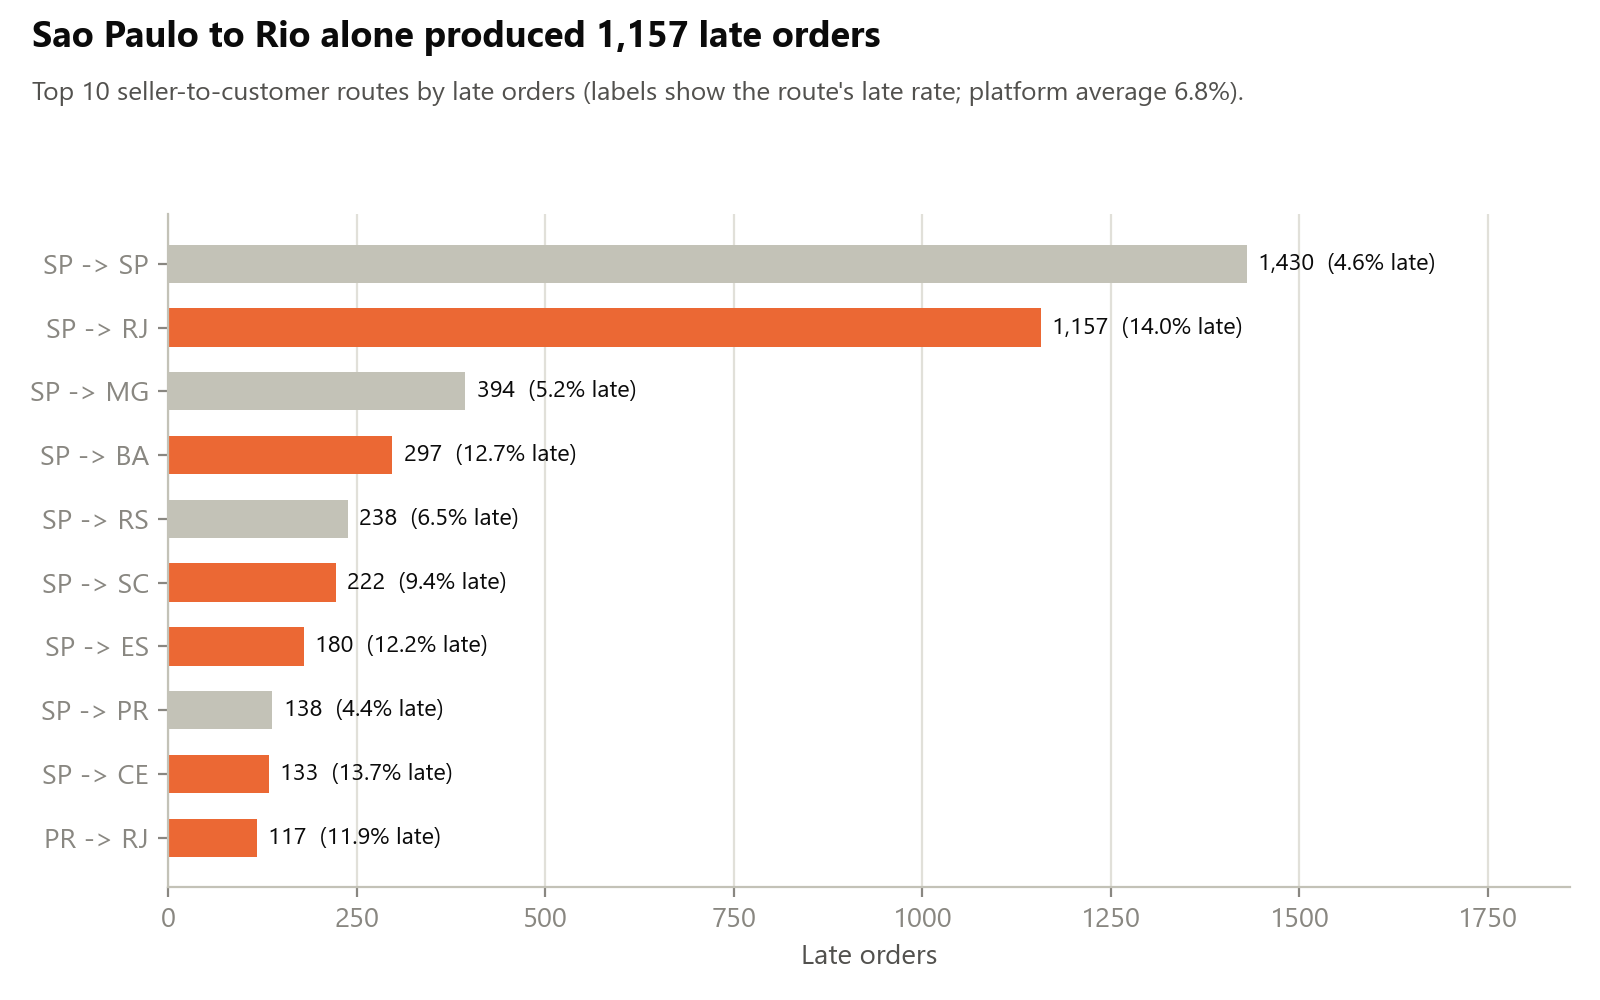

In [17]:
chart("06_routes_late_orders.png")

In [18]:
insight(f"{A['worst_state']} has the highest late rate ({A['worst_state_late_rate_pct']}%). "
        "SP -> RJ produces the most late orders among routes that are worse than average.")

**Insight:** AL has the highest late rate (21.46%). SP -> RJ produces the most late orders among routes that are worse than average.

## Q5. Are late orders concentrated in a few sellers?

In [19]:
run("q09_seller_concentration")

-- question: Q5. What share of late orders comes from the top 10% / 20% of sellers (ranked by number of late orders)?
WITH seller_late AS (
    SELECT seller_id,
           COUNT(*)     AS pairs,
           SUM(is_late) AS late_pairs
    FROM analysis_order_sellers
    GROUP BY seller_id
),
ranked AS (
    SELECT *,
           ROW_NUMBER() OVER (ORDER BY late_pairs DESC, pairs DESC) AS seller_rank,
           COUNT(*)        OVER ()                                  AS n_sellers,
           SUM(late_pairs) OVER ()                                  AS total_late,
           SUM(pairs)      OVER ()                                  AS total_pairs
    FROM seller_late
),
segments AS (
    SELECT 'Top 10% of sellers' AS segment, 1 AS sort_order, 0.10 AS cutoff
    UNION ALL SELECT 'Top 20% of sellers', 2, 0.20
    UNION ALL SELECT 'All sellers',        3, 1.00
)
SELECT
    g.segment,
    COUNT(*)                                             AS sellers,
    SUM(r.late_pairs)                    

,segment,sellers,late_orders,share_of_late_orders_pct,share_of_order_volume_pct,late_rate_pct
0,Top 10% of sellers,294,4826,73.75,63.29,7.82
1,Top 20% of sellers,589,5721,87.42,78.65,7.46
2,All sellers,2945,6544,100.00,100.00,6.71


In [20]:
run("q10_sla_breach_vs_late")

-- question: Q5. How does a seller SLA breach relate to lateness and reviews?
SELECT
    CASE WHEN sla_breach = 1 THEN 'SLA breached' ELSE 'SLA met' END AS seller_sla,
    COUNT(*)                                             AS order_seller_pairs,
    ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2)   AS share_of_pairs_pct,
    ROUND(100.0 * AVG(is_late), 2)                       AS late_rate_pct,
    ROUND(100.0 * AVG(is_bad_review), 2)                 AS bad_review_pct_all_pairs
FROM analysis_order_sellers
WHERE sla_breach IS NOT NULL
GROUP BY seller_sla
ORDER BY seller_sla;


,seller_sla,order_seller_pairs,share_of_pairs_pct,late_rate_pct,bad_review_pct_all_pairs
0,SLA breached,8643,8.86,20.98,23.73
1,SLA met,88897,91.14,5.32,12.17


In [21]:
run("q11_seller_breach_band", show_sql=False)

,seller_breach_band,sellers,order_seller_pairs,late_rate_pct
0,1. 0%,97,5449,4.48
1,2. 0-5%,220,33015,5.49
2,3. 5-15%,187,29384,7.03
3,4. over 15%,121,13586,10.00


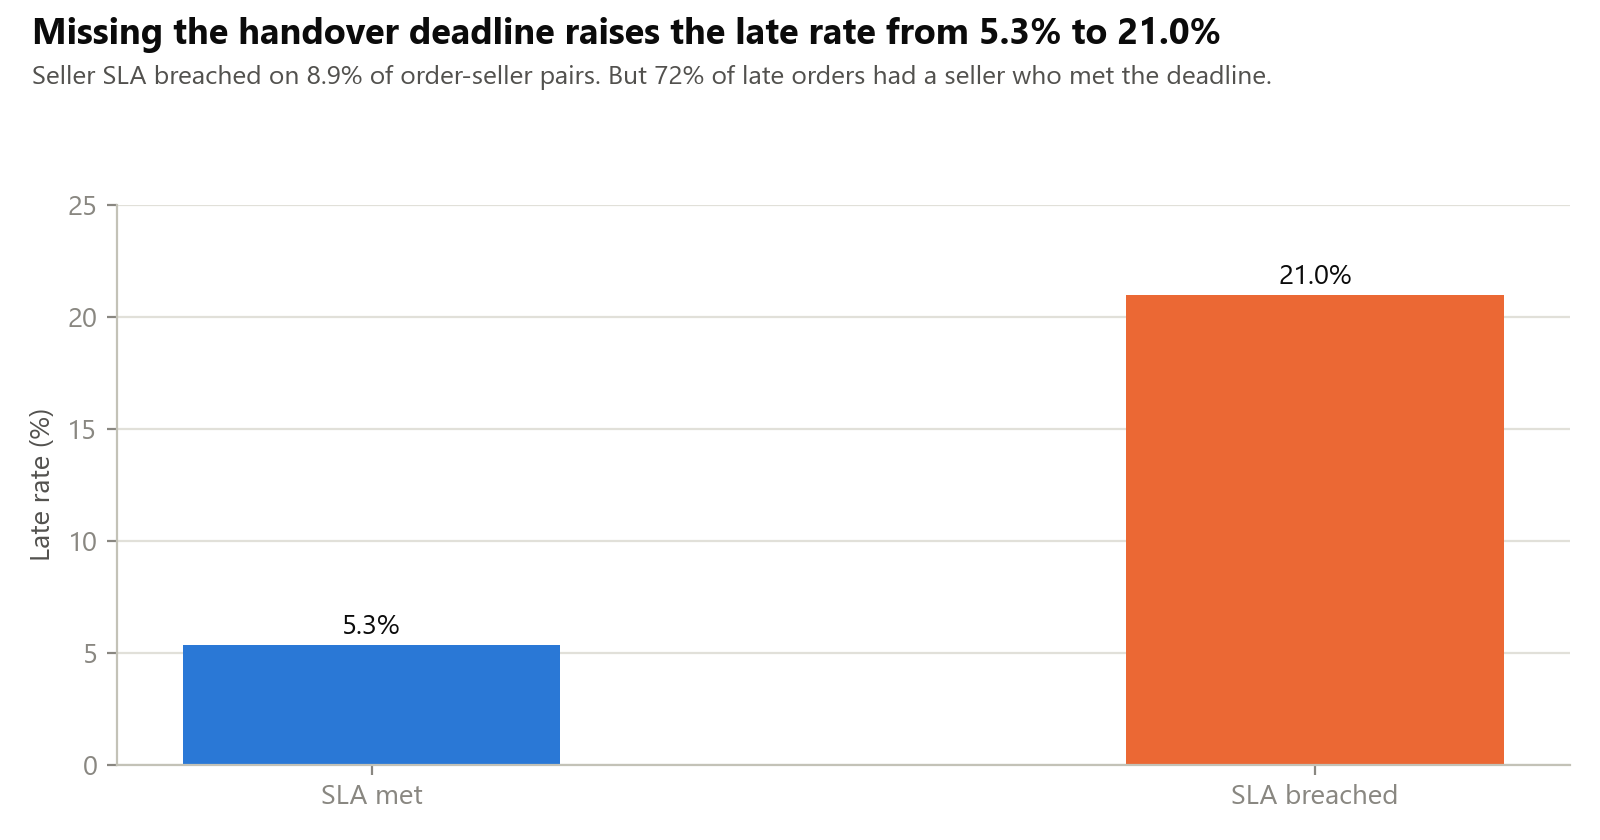

In [22]:
chart("04_sla_breach_vs_late.png", width=600)

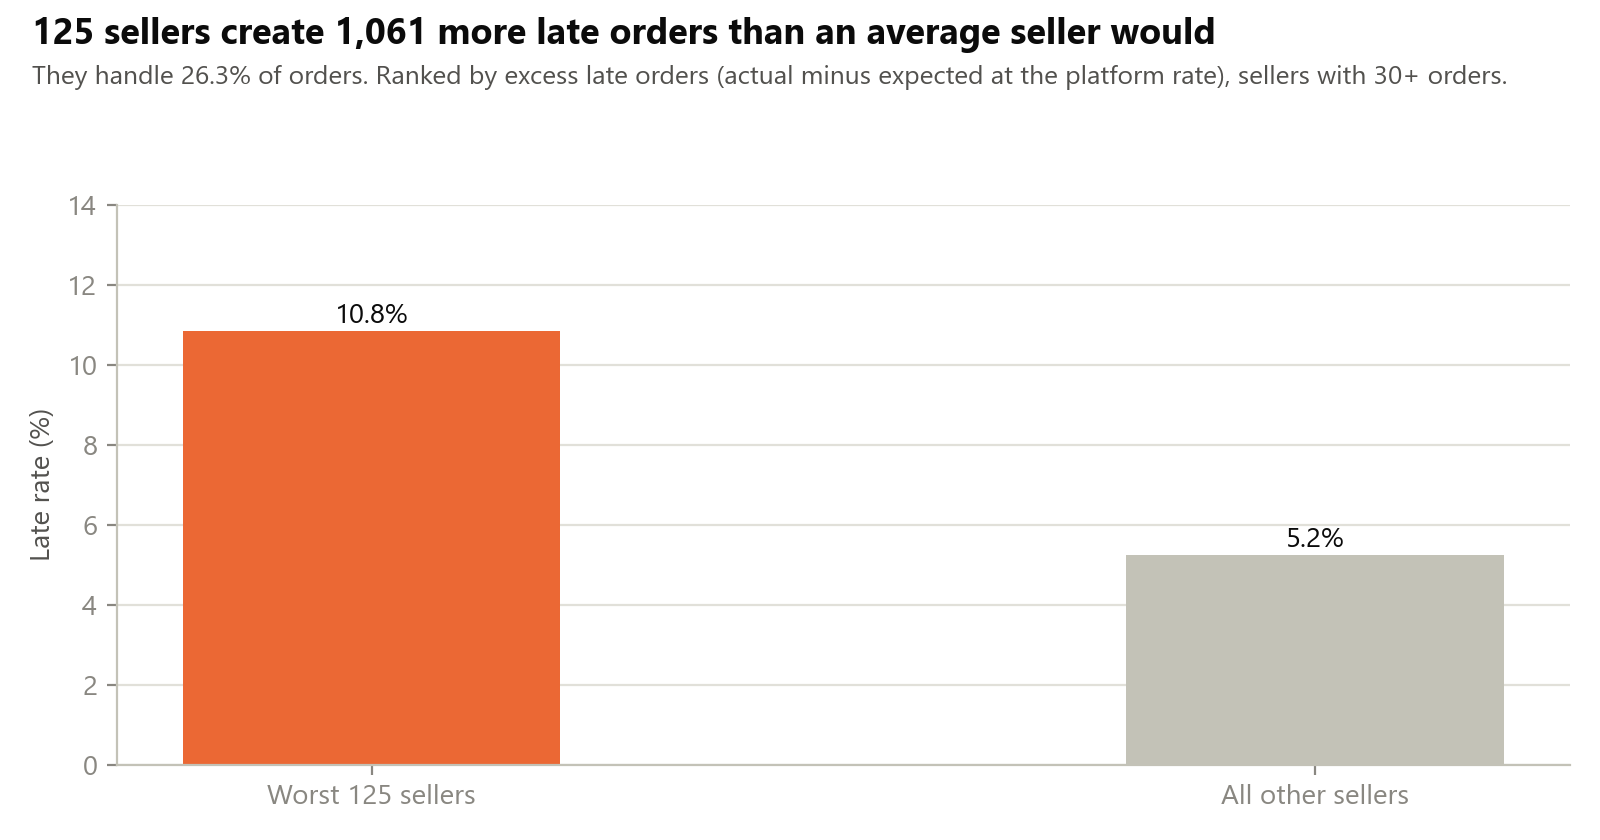

In [23]:
chart("07_worst_sellers.png", width=600)

In [24]:
insight(f"The top 20% of sellers by late count produce {A['top20_sellers_share_of_late_pct']}% of late orders "
        f"but also {A['top20_sellers_share_of_volume_pct']}% of volume, so I rank by excess late orders instead: "
        f"{I['worst_sellers_n']} sellers create {I['worst_sellers_excess_late']:,} excess late orders.")

**Insight:** The top 20% of sellers by late count produce 87.42% of late orders but also 78.65% of volume, so I rank by excess late orders instead: 125 sellers create 1,061 excess late orders.

## Q6. Which product categories have the highest late rates?

In [25]:
run("q12_category_late").head(10)

-- question: Q6. Which product categories have the highest late rates (min 300 orders)?
-- Category = category of the most expensive item in the order.
SELECT
    main_category,
    COUNT(*)                                             AS orders,
    SUM(is_late)                                         AS late_orders,
    ROUND(100.0 * AVG(is_late), 2)                       AS late_rate_pct,
    ROUND(AVG(freight_value), 2)                         AS avg_freight_brl
FROM analysis_orders
GROUP BY main_category
HAVING COUNT(*) >= 300
ORDER BY late_rate_pct DESC;


,main_category,orders,late_orders,late_rate_pct,avg_freight_brl
0,audio,342,41,11.99,16.43
1,home_confort,370,35,9.46,23.60
2,baby,2752,224,8.14,24.17
3,office_furniture,1245,101,8.11,53.69
4,electronics,2501,192,7.68,18.28
5,furniture_living_room,409,31,7.58,44.09
6,musical_instruments,608,46,7.57,29.41
7,health_beauty,8576,647,7.54,20.79
8,bed_bath_table,9180,687,7.48,22.02
9,construction_tools_construction,724,54,7.46,27.93


In [26]:
insight(f"Only {A['worst_category']} stands out ({A['worst_category_late_rate_pct']}%); most categories "
        "sit close to the platform rate, so category is not a main driver.")

**Insight:** Only audio stands out (11.99%); most categories sit close to the platform rate, so category is not a main driver.

## Q7. Is the delivery promise accurate?

In [27]:
run("q13_promise_accuracy_distribution")

-- question: Q7. How accurate is the delivery promise? Distribution of (estimated - actual) days.
SELECT
    CASE WHEN -delay_days < 0   THEN '1. Late (after estimate)'
         WHEN -delay_days <= 6  THEN '2. 0-6 days early'
         WHEN -delay_days <= 13 THEN '3. 7-13 days early'
         WHEN -delay_days <= 20 THEN '4. 14-20 days early'
         ELSE                        '5. 21+ days early'
    END                                                  AS days_before_estimate,
    COUNT(*)                                             AS orders,
    ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2)   AS share_pct
FROM analysis_orders
GROUP BY days_before_estimate
ORDER BY days_before_estimate;


,days_before_estimate,orders,share_pct
0,1. Late (after estimate),6531,6.79
1,2. 0-6 days early,13790,14.33
2,3. 7-13 days early,34065,35.41
3,4. 14-20 days early,28577,29.70
4,5. 21+ days early,13240,13.76


In [28]:
run("q14_promise_by_state", show_sql=False)

,customer_state,orders,avg_promised_days,avg_actual_days,avg_days_early,late_rate_pct
0,AL,396,32.5,24.5,8.6,21.46
1,MA,713,30.3,21.5,9.4,17.53
2,SE,332,30.6,21.4,9.9,15.36
3,ES,1992,25.5,15.8,10.5,10.74
4,CE,1273,31.2,21.2,10.6,13.83
5,BA,3253,29.4,19.3,10.8,12.17
6,SP,40399,19.1,8.7,11.0,4.50
7,MS,701,26.0,15.6,11.1,9.70
8,PI,475,30.0,19.4,11.2,13.89
9,SC,3537,25.7,14.9,11.4,8.23


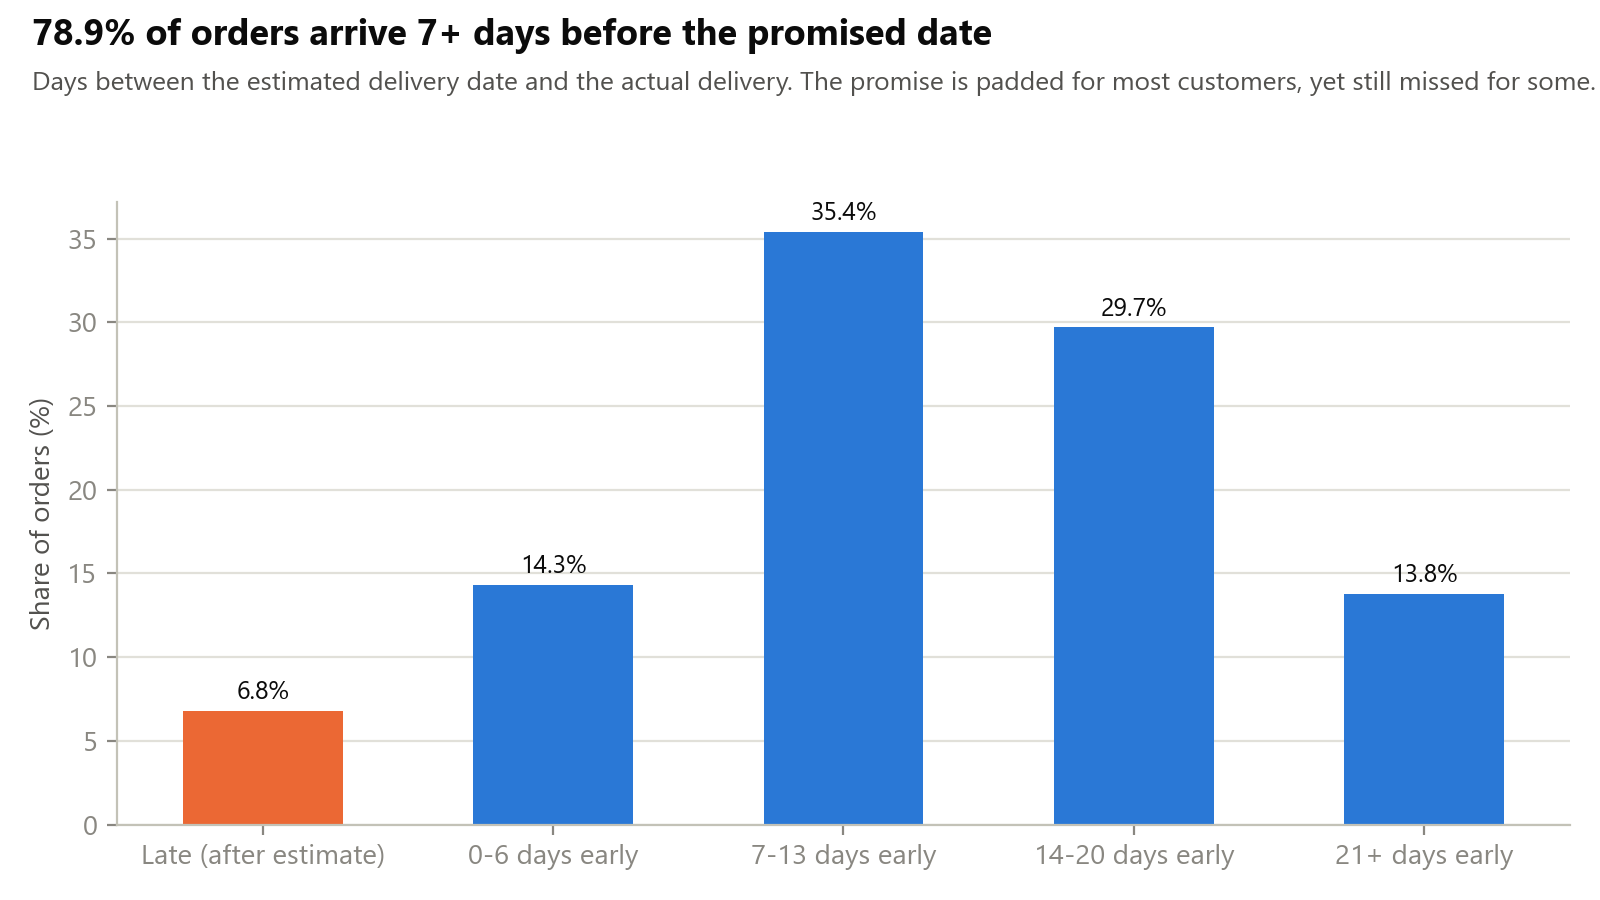

In [29]:
chart("08_promise_accuracy.png")

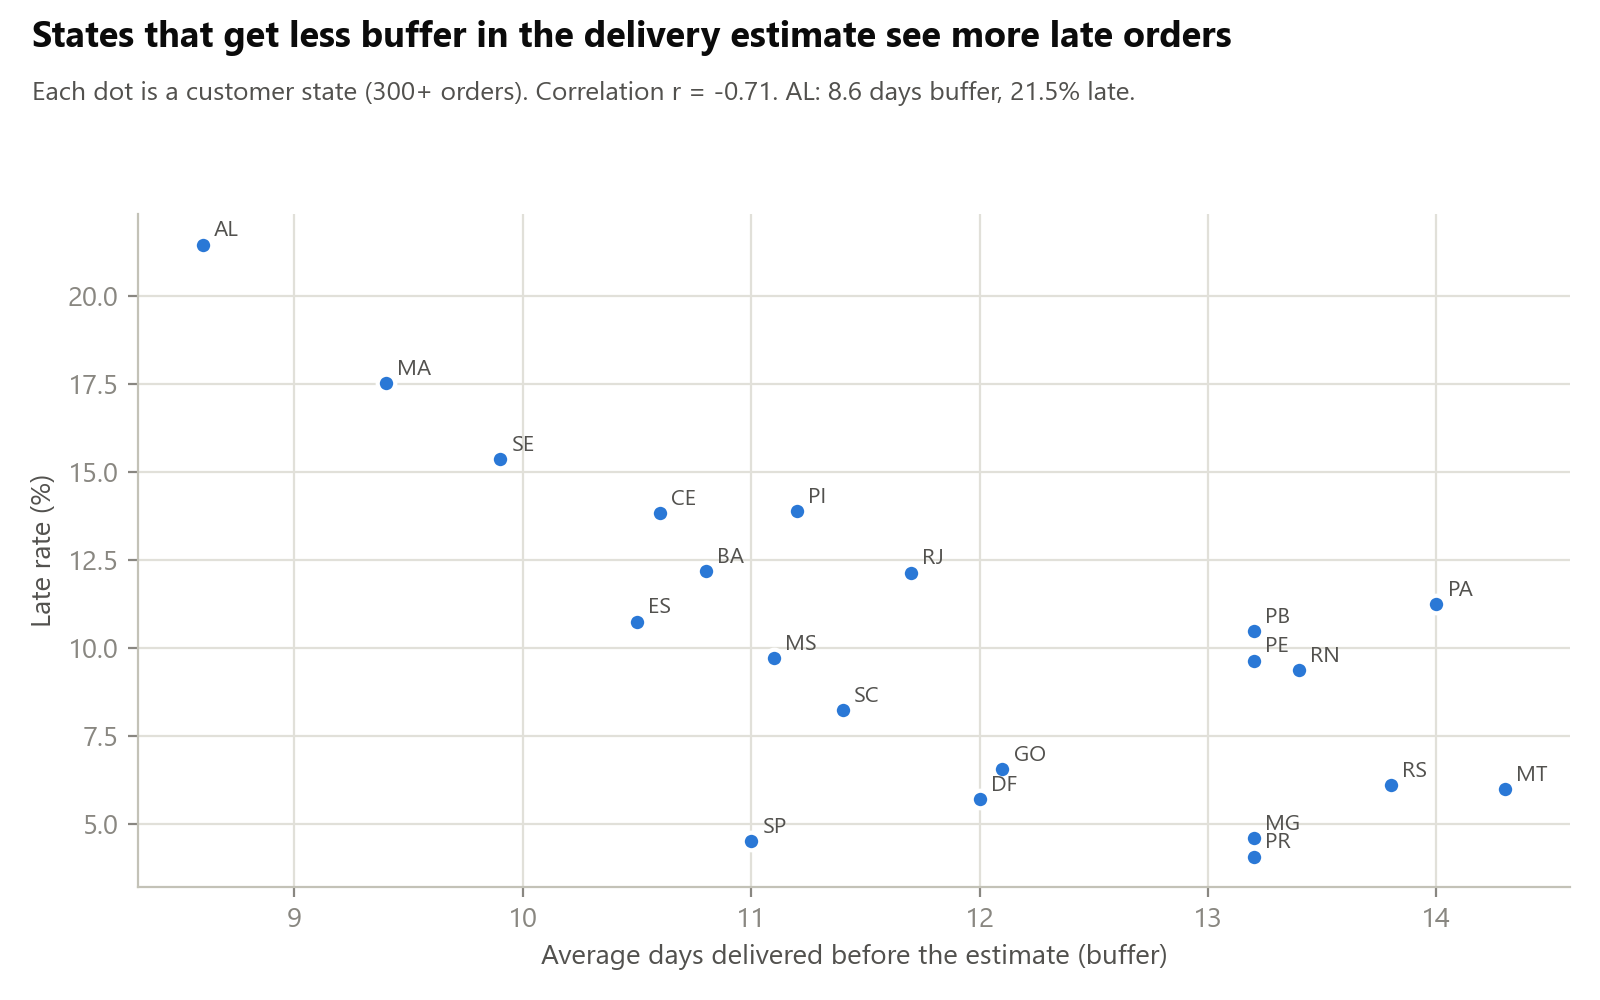

In [30]:
chart("09_buffer_vs_late_by_state.png", width=650)

In [31]:
insight(f"{A['pct_orders_arrived_7plus_days_early']}% of orders arrive 7+ days early, yet "
        f"{A['least_padded_state']} gets only {A['least_padded_state_days_early']} days of buffer and is late "
        f"{A['least_padded_state_late_rate_pct']}% of the time (r = {m['charts']['state_buffer_vs_late_corr']}).")

**Insight:** 78.87% of orders arrive 7+ days early, yet AL gets only 8.6 days of buffer and is late 21.46% of the time (r = -0.71).

## Q8. Do customers come back after a late first order?

In [32]:
run("q15_repeat_purchase")

-- question: Q8. Do customers whose first order was late come back less often?
-- Repeat = the same customer_unique_id has another delivered order on a later date.
-- Directional only: very few Olist customers ever buy twice.
WITH ranked AS (
    SELECT customer_unique_id,
           is_late,
           date(order_purchase_timestamp) AS purchase_date,
           ROW_NUMBER() OVER (PARTITION BY customer_unique_id
                              ORDER BY order_purchase_timestamp, order_id) AS order_seq,
           MAX(date(order_purchase_timestamp)) OVER (PARTITION BY customer_unique_id) AS last_purchase_date
    FROM analysis_orders
),
first_orders AS (
    SELECT customer_unique_id,
           is_late AS first_order_late,
           CASE WHEN last_purchase_date > purchase_date THEN 1 ELSE 0 END AS is_repeat
    FROM ranked
    WHERE order_seq = 1
)
SELECT
    CASE WHEN first_order_late = 1 THEN 'First order late' ELSE 'First order on time' END AS first_order,
    COUNT(*)                

,first_order,customers,repeat_customers,repeat_rate_pct
0,First order late,6352,103,1.62
1,First order on time,86744,1902,2.19
2,All customers,93096,2005,2.15


In [33]:
insight(f"{A['repeat_rate_first_late_pct']}% repeat after a late first order vs "
        f"{A['repeat_rate_first_ontime_pct']}% after an on-time one. Only {A['repeat_rate_all_pct']}% of "
        "customers buy again, so this is directional.")

**Insight:** 1.62% repeat after a late first order vs 2.19% after an on-time one. Only 2.15% of customers buy again, so this is directional.

## Impact estimate

In [34]:
pd.read_csv(ROOT / "results" / "tables" / "impact_scenarios.csv", index_col=0)

,avoided_late_sellers,avoided_late_routes,avoided_late_total,avoided_late_pct_of_all_late,bad_reviews_prevented,avoided_late_per_year,bad_reviews_prevented_per_year,late_rate_after_pct
conservative,531,222,752,11.5,391,451,234,5.94
expected,1061,352,1413,21.6,734,848,440,5.26


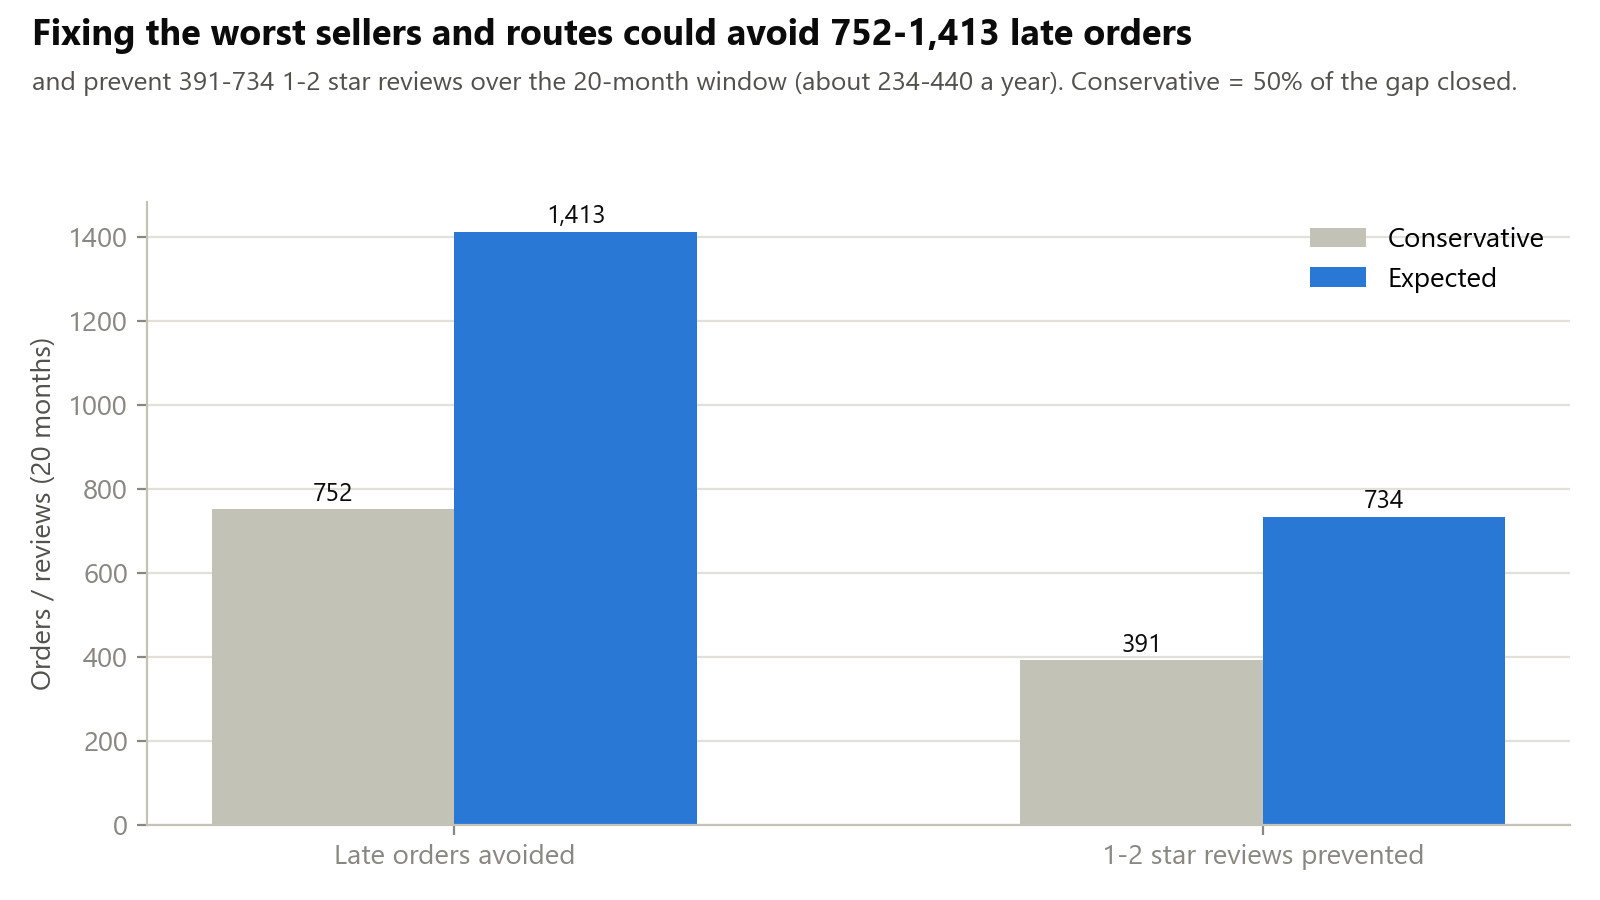

In [35]:
chart("10_impact_estimate.png", width=650)

In [36]:
c, e = I["conservative"], I["expected"]
insight(f"Bringing the worst sellers and routes to the platform average avoids {c['avoided_late_total']:,}-"
        f"{e['avoided_late_total']:,} late orders and {c['bad_reviews_prevented']:,}-{e['bad_reviews_prevented']:,} "
        "1-2 star reviews over 20 months. Assumptions are in src/03_impact.py.")

**Insight:** Bringing the worst sellers and routes to the platform average avoids 752-1,413 late orders and 391-734 1-2 star reviews over 20 months. Assumptions are in src/03_impact.py.

In [37]:
conn.close()